[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/05_matrices.ipynb)

*Math for Data Science & ML · Notebook 5 of 10*

# Matrices

Tables of numbers that transform vectors: multiplication, transpose, determinant, inverse, solving systems, rank — and the matrix form of a neural-network layer and linear regression.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A matrix is a machine that transforms space: it stretches, rotates and squashes arrows.

**What interviewers really test here:** Matrix multiplication shapes, inverse, rank and solving systems.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What is a matrix? *(Basics)*
- [ ] 2. Multiplying a matrix by a vector *(Basics)*
- [ ] 3. Matrix multiplication, one entry at a time *(Basics)*
- [ ] 4. Multiplying two matrices *(Core)*
- [ ] 5. Determinant and inverse *(Core)*
- [ ] 6. A matrix moves space *(Core)*
- [ ] 7. Gaussian elimination by hand *(Core)*
- [ ] 8. The inverse by hand *(Core)*
- [ ] 9. Rank, covariance and linear regression in matrix form *(Advanced)*
- [ ] 10. Rank: how much information is really there? *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Definitions and special matrices

| Matrix | Property |
| --- | --- |
| Square | n × n |
| Identity I | 1 on the diagonal, 0 elsewhere; AI = IA = A |
| Diagonal | non-zero only on the diagonal; scales each axis |
| Symmetric | A = Aᵀ (covariance matrices) |
| Triangular | zeros below (upper) or above (lower) the diagonal |
| Orthogonal | QᵀQ = I; rotations and reflections, preserve lengths |
| Singular | det = 0, no inverse |

### Operations and rules

- (AB)ᵢⱼ = Σₖ AᵢₖBₖⱼ; defined when columns of A = rows of B.
- Associative (AB)C = A(BC), distributive A(B + C) = AB + AC, **not commutative**.
- (AB)ᵀ = BᵀAᵀ; (AB)⁻¹ = B⁻¹A⁻¹.
- Trace: tr(A) = Σ Aᵢᵢ; tr(AB) = tr(BA).
- Cost of multiplying n × n matrices naively: n³ multiplications.

### Determinant

2 × 2: ad − bc. 3 × 3: cofactor expansion along a row. Properties: det(AB) = det A · det B; det Aᵀ = det A; swapping two rows flips the sign; a row of zeros or two equal rows gives 0; det(A⁻¹) = 1/det A. |det A| is the factor by which A scales area (volume); the sign tells whether orientation flips.

### Systems, inverse and rank

A·x = b has a unique solution ⇔ A is square with det A ≠ 0 ⇔ rank A = n ⇔ A is invertible ⇔ the columns are linearly independent (the **invertible matrix theorem**).




- **Gaussian elimination** reduces A to triangular form with row operations, then back-substitutes: O(n³).
- **Rank** = number of pivots = dimension of the column space. rank + nullity = number of columns.
- Over-determined systems (more equations than unknowns, as in regression) are solved by **least squares**: minimise ‖Xw − y‖², giving XᵀXw = Xᵀy.

### Matrices in machine learning

| Where | Matrix |
| --- | --- |
| Dataset | X: n examples × d features |
| Linear / logistic regression | predictions Xw |
| Neural-network layer | activation(Wx + b); a batch: activation(XWᵀ + b) |
| Images | height × width (× colour channels) |
| Covariance / correlation | XᵀX/(n − 1) on centred data |
| Recommenders | user × item ratings, factorised into two thin matrices |
| Graphs | adjacency matrix; Markov transition matrix |

---
# Part 2: Lessons, step by step

## Lesson 1: What is a matrix?

*Level: Basics*

A **matrix** is a rectangle of numbers with rows and columns. A 2 × 3 matrix has 2 rows and 3 columns. Entry A~ij sits in row i, column j.



Two ways to think of one:




- **A table of data**: each row is one example (a house), each column one feature (size, rooms, age). A dataset with 1000 houses and 3 features is a 1000 × 3 matrix, usually called **X**.
- **A machine that transforms vectors**: multiply a vector by a matrix and it gets rotated, stretched or squashed.



Adding matrices and multiplying by a number work entry by entry. The **transpose** Aᵀ flips rows into columns.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [2]:
def matrix_demo():
    X = np.array([[120, 3, 15], [80, 2, 30], [150, 4, 5]])
    shape = X.shape
    first_house = X[0]
    all_sizes = X[:, 0]
    XT = X.T


matrix_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q7](#q7), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 2: Multiplying a matrix by a vector

*Level: Basics*

A·v: take the dot product of **each row** of A with v. Each row gives one number of the answer.



```python
[1 2] [5]   [1·5 + 2·6]   [17]
[3 4] [6] = [3·5 + 4·6] = [39]
```



Why care? A whole layer of a neural network is one matrix-vector product: each row of W holds one neuron's weights, so W·x computes every neuron at once.



Geometrically, a 2 × 2 matrix moves every point of the plane: the first column is where [1, 0] lands, the second column is where [0, 1] lands.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

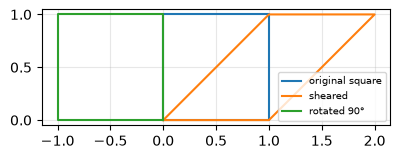

In [3]:
SQUARE = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]], dtype=float)


def transform_demo():
    shear = np.array([[1, 1], [0, 1]])
    rotate = np.array([[0, -1], [1, 0]])
    sheared = SQUARE @ shear.T
    rotated = SQUARE @ rotate.T
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.plot(SQUARE[:, 0], SQUARE[:, 1], label="original square")
    ax.plot(sheared[:, 0], sheared[:, 1], label="sheared")
    ax.plot(rotated[:, 0], rotated[:, 1], label="rotated 90°")
    ax.set_aspect("equal")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)


transform_demo()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q15](#q15), [Q14](#q14), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 3: Matrix multiplication, one entry at a time

*Level: Basics*

```python
A = [[1, 2, 3],      B = [[ 7,  8],
     [4, 5, 6]]           [ 9, 10],
                          [11, 12]]
```



**First check shapes:** (2 × **3**)·(**3** × 2). The inner numbers match, and the outer ones give the result's shape: 2 × 2.



**Each entry is a row of A dotted with a column of B:**



| Entry | Row of A · column of B | Value |
| --- | --- | --- |
| (1, 1) | 1·7 + 2·9 + 3·11 | 58 |
| (1, 2) | 1·8 + 2·10 + 3·12 | 64 |
| (2, 1) | 4·7 + 5·9 + 6·11 | 139 |
| (2, 2) | 4·8 + 5·10 + 6·12 | 154 |



Result: [[58, 64], [139, 154]].



**BA is a different thing:** here it would be 3 × 3. Order matters in matrix multiplication.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def multiply_by_hand():
    A = np.array([[1, 2, 3], [4, 5, 6]])
    B = np.array([[7, 8], [9, 10], [11, 12]])
    first_entry = A[0] @ B[:, 0]
    AB = A @ B
    BA_shape = (B @ A).shape
    shapes = (A.shape, B.shape, AB.shape)


multiply_by_hand()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q3](#q3), [Q1](#q1), [Q2](#q2), [Q4](#q4), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 4: Multiplying two matrices

*Level: Core*

A·B: entry (i, j) = row i of A · column j of B. Sizes must fit: (m × **n**) · (**n** × p) → m × p.




- Order matters: A·B ≠ B·A in general.
- The **identity matrix** I (1s on the diagonal) does nothing: A·I = A.
- Multiplying matrices = doing one transformation then another. Aⁿ = applying A n times (used in Markov chains).



**Element-wise** product (`A * B`) is different from **matrix** product (`A @ B`) — a classic bug.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
def matmul_demo():
    A = np.array([[1, 2], [3, 4]])
    B = np.array([[5, 6], [7, 8]])
    AB = A @ B
    BA = B @ A
    elementwise = A * B
    I = np.eye(2, dtype=int)
    same = A @ I


matmul_demo()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q4](#q4), [Q13](#q13), [Q8](#q8), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 5: Determinant and inverse

*Level: Core*

The **determinant** of a 2 × 2 matrix [[a, b], [c, d]] is ad − bc. It measures how much the matrix scales **area**: det = 2 doubles areas, det = 0 squashes the plane flat onto a line (information is lost).



The **inverse** A⁻¹ undoes A: A⁻¹A = I. It exists only when det ≠ 0. For 2 × 2: A⁻¹ = (1/det)·[[d, −b], [−c, a]].



A system of equations A·x = b is solved by x = A⁻¹b — in practice with `np.linalg.solve` (Gaussian elimination), which is faster and more accurate than computing the inverse.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

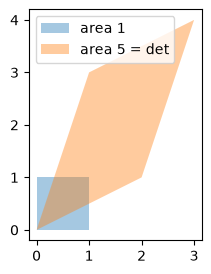

In [6]:
SQUARE = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]], dtype=float)


def det_demo():
    A = np.array([[2.0, 1.0], [1.0, 3.0]])
    det = np.linalg.det(A)
    A_inv = np.linalg.inv(A)
    check = A_inv @ A
    shape = SQUARE @ A.T
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.fill(SQUARE[:, 0], SQUARE[:, 1], alpha=0.4, label="area 1")
    ax.fill(shape[:, 0], shape[:, 1], alpha=0.4, label=f"area {det:.0f} = det")
    ax.set_aspect("equal")
    ax.legend()


det_demo()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q10](#q10), [Q11](#q11), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 6: A matrix moves space

*Level: Core*

Here's a very useful idea: **the columns of a matrix show where the basic arrows land.** In [[a, b], [c, d]], (1, 0) goes to (a, c) and (0, 1) goes to (b, d).



| Matrix | Effect | det |
| --- | --- | --- |
| [[2, 0], [0, 2]] | doubles everything | 4 |
| [[2, 0], [0, 1]] | stretches sideways | 2 |
| [[0, −1], [1, 0]] | rotates 90° | 1 |
| [[1, 0], [0, −1]] | mirrors | −1 |
| [[1, 1], [0, 1]] | shears | 1 |
| [[1, 2], [2, 4]] | squashes onto a line | 0 |



**The determinant is the area factor.** A negative sign means the shape flipped. Zero means space collapsed, and no matrix can undo that, which is why det = 0 means no inverse.



A neural network layer does exactly this, stretching and rotating space, then bending it with an activation, until the classes can be separated.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

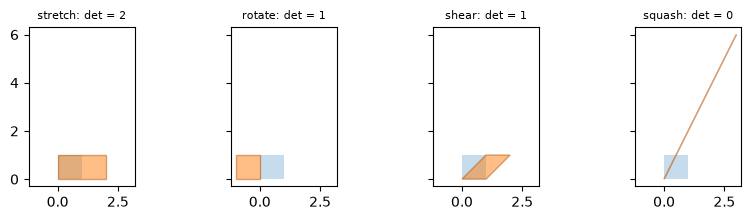

In [7]:
def space_moves():
    square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]], dtype=float)
    matrices = {"stretch": [[2, 0], [0, 1]], "rotate": [[0, -1], [1, 0]], "shear": [[1, 1], [0, 1]], "squash": [[1, 2], [2, 4]]}
    fig, axes = plt.subplots(1, 4, figsize=(8.5, 2.3), sharex=True, sharey=True)
    for ax, (name, M) in zip(axes, matrices.items()):
        M = np.array(M, dtype=float)
        moved = square @ M.T
        ax.fill(square[:, 0], square[:, 1], alpha=0.25)
        ax.fill(moved[:, 0], moved[:, 1], alpha=0.5, edgecolor="#b45309")
        ax.set_title(f"{name}: det = {np.linalg.det(M):.0f}", fontsize=8)
        ax.set_aspect("equal")
    fig.tight_layout()


space_moves()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q17](#q17), [Q6](#q6), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 7: Gaussian elimination by hand

*Level: Core*

Solve this system:



```python
x +  y +  z = 6
    2y + 5z = −4
2x + 5y −  z = 27
```



#### Step 1: remove x from row 3



Row 3 − 2 × Row 1 gives 3y − 3z = 15, or y − z = 5.



#### Step 2: remove y



From y − z = 5 we have y = z + 5. Put that in row 2: 2(z + 5) + 5z = −4, so 7z = −14 and **z = −2**.



#### Step 3: work backwards



- y = −2 + 5 = **3**
- x = 6 − 3 − (−2) = **5**



#### Step 4: check



5 + 3 − 2 = 6 ✓, 6 − 10 = −4 ✓, 10 + 15 + 2 = 27 ✓.



The allowed moves are: swap rows, multiply a row, add a multiple of one row to another. None of them changes the solution. `np.linalg.solve` does the same thing, choosing the largest values as pivots to limit rounding errors.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def elimination_steps():
    A = np.array([[1.0, 1, 1], [0, 2, 5], [2, 5, -1]])
    b = np.array([6.0, -4, 27])
    row3 = np.append(A[2], b[2]) - 2 * np.append(A[0], b[0])
    z = -2.0
    y = z + 5
    x = 6 - y - z
    answer = np.linalg.solve(A, b)
    check = A @ answer


elimination_steps()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 8: The inverse by hand

*Level: Core*

A = [[4, 7], [2, 6]].



1. **Determinant:** 4·6 − 7·2 = 10.
2. **Swap the diagonal, negate the others:** [[6, −7], [−2, 4]].
3. **Divide by det:** A⁻¹ = [[0.6, −0.7], [−0.2, 0.4]].
4. **Check:** the first entry of A·A⁻¹ is 4(0.6) + 7(−0.2) = 1 ✓, and multiplying fully gives the identity.



#### Using it



To solve A·x = (1, 2): x = A⁻¹·(1, 2) = (0.6 − 1.4, −0.2 + 0.8) = (−0.8, 0.6).



#### Useful rules



- (AB)⁻¹ = B⁻¹A⁻¹: undo in reverse order, like taking off socks after shoes.
- (AB)ᵀ = BᵀAᵀ: the same reversal for the transpose.
- A symmetric matrix has A = Aᵀ. Covariance matrices are always symmetric.



In practice, prefer `solve` to computing an inverse: it's faster and more accurate.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [9]:
def inverse_by_hand():
    A = np.array([[4.0, 7], [2, 6]])
    det = A[0, 0] * A[1, 1] - A[0, 1] * A[1, 0]
    inverse = np.array([[A[1, 1], -A[0, 1]], [-A[1, 0], A[0, 0]]]) / det
    identity = (A @ inverse).round(10)
    answer = inverse @ np.array([1.0, 2.0])
    same_answer = np.linalg.solve(A, [1.0, 2.0])


inverse_by_hand()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q7](#q7), [Q13](#q13), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 9: Rank, covariance and linear regression in matrix form

*Level: Advanced*

The **rank** is the number of truly independent rows (or columns). If a feature is just 2 × another feature, it adds no information and the rank drops.



With centred data X (each column minus its mean), **XᵀX / (n − 1)** is the **covariance matrix**: diagonal = variances, off-diagonal = how pairs of features move together. It is the starting point of PCA (next topic).



**Linear regression** for all features at once: find w so that X·w ≈ y. The best w (least squares) solves the **normal equation** XᵀX·w = Xᵀy. One line of matrix algebra replaces pages of formulas.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

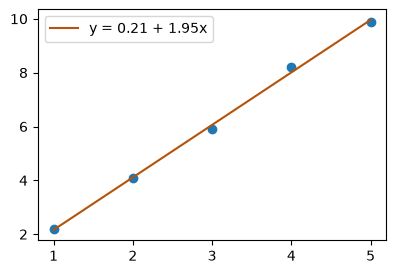

In [10]:
def regression_demo():
    x = np.array([1, 2, 3, 4, 5], dtype=float)
    y = np.array([2.2, 4.1, 5.9, 8.2, 9.9])
    X = np.column_stack([np.ones_like(x), x])
    w = np.linalg.solve(X.T @ X, X.T @ y)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.scatter(x, y)
    ax.plot(x, X @ w, color="#b45309", label=f"y = {w[0]:.2f} + {w[1]:.2f}x")
    ax.legend()


regression_demo()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q19](#q19), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 10: Rank: how much information is really there?

*Level: Advanced*

Rank counts the truly independent rows (or columns). Rows and columns always give the same number.



#### Worked example



```python
[[1, 2, 3],
 [4, 5, 6],
 [7, 8, 9]]
```



Row 3 = 2 × Row 2 − Row 1: for example 2(4) − 1 = 7. So the third row adds nothing, and the **rank is 2**, not 3. The determinant is 0.



#### What it means in practice



- **Duplicate features** reduce the rank, so XᵀX has no inverse.
- **Fewer rows than columns** also lowers the rank, so many different weights fit equally well.
- **Recommenders:** a huge user × item table is often well described by a low-rank one, because tastes follow a few patterns.



The chart shows a table of 100 rows × 5 features. Though it has 5 columns, it's built from only 2 hidden patterns, so nearly all the information sits in the first 2 singular values.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

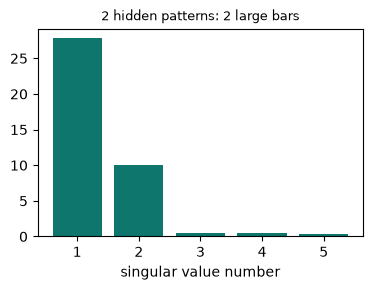

In [11]:
def low_rank_table():
    r = np.random.default_rng(0)
    hidden = r.normal(size=(100, 2))
    mix = r.normal(size=(2, 5))
    table = hidden @ mix + r.normal(0, 0.05, (100, 5))
    singular_values = np.linalg.svd(table, compute_uv=False)
    exact_rank = np.linalg.matrix_rank(hidden @ mix)
    three_by_three = np.linalg.matrix_rank([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
    fig, ax = plt.subplots(figsize=(4.2, 2.7))
    ax.bar(range(1, 6), singular_values, color="#0f766e")
    ax.set_xlabel("singular value number")
    ax.set_title("2 hidden patterns: 2 large bars", fontsize=9)


low_rank_table()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q19](#q19), [Q20](#q20), [Q15](#q15), [Q16](#q16). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Transpose

🟢 Warm-up · *Rows become columns*

Return the transpose of matrix A.

**Examples**

- `A = [[1, 2, 3], [4, 5, 6]]` → `[[1, 4], [2, 5], [3, 6]]`
- `A = [[7]]` → `[[7]]`

In [ ]:
def transpose(A):
    """
    Return the transpose of matrix A.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(transpose, [
    (([[1, 2, 3], [4, 5, 6]],), [[1, 4], [2, 5], [3, 6]]),
    (([[7]],), [[7]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

New row j is old column j: build it with nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`A.T`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** New row j is old column j: build it with nested loops.

```python
def transpose(A):
    rows, cols = len(A), len(A[0])
    T = []
    for j in range(cols):
        new_row = []
        for i in range(rows):
            new_row.append(A[i][j])
        T.append(new_row)
    return T
```

**Cost:** O(m·n) time, O(m·n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `A.T`.

```python
def transpose(A):
    return np.array(A).T
```

**Cost:** O(1) view time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: New row j is old column j: build it with nested loops. That costs O(m·n) time and O(m·n) space."

"I can do better: `A.T`. That's O(1) view time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/transpose)

<a id="q2"></a>
### Q2. Add Two Matrices

🟢 Warm-up · *Entry by entry*

Return A + B (same shape).

**Examples**

- `A = [[1, 2], [3, 4]], B = [[5, 6], [7, 8]]` → `[[6, 8], [10, 12]]`
- `A = [[1, -1]], B = [[-1, 1]]` → `[[0, 0]]`

In [ ]:
def mat_add(A, B):
    """
    Return A + B (same shape).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mat_add, [
    (([[1, 2], [3, 4]], [[5, 6], [7, 8]]), [[6, 8], [10, 12]]),
    (([[1, -1]], [[-1, 1]]), [[0, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops adding matching entries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`A + B` on arrays.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Nested loops adding matching entries.

```python
def mat_add(A, B):
    return [[A[i][j] + B[i][j] for j in range(len(A[0]))] for i in range(len(A))]
```

**Cost:** O(m·n) time, O(m·n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `A + B` on arrays.

```python
def mat_add(A, B):
    return np.array(A) + np.array(B)
```

**Cost:** O(m·n) time, O(m·n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops adding matching entries. That costs O(m·n) time and O(m·n) space."

"I can do better: `A + B` on arrays. That's O(m·n) time and O(m·n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/add-two-matrices)

<a id="q3"></a>
### Q3. Matrix Times Vector

🟢 Warm-up · *Each row · the vector*

Return A·v.

**Examples**

- `A = [[1, 2], [3, 4]], v = [5, 6]` → `[17, 39]`
- `A = [[1, 0, 0], [0, 2, 0]], v = [3, 3, 3]` → `[3, 6]`

In [ ]:
def mat_vec(A, v):
    """
    Return A·v.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mat_vec, [
    (([[1, 2], [3, 4]], [5, 6]), [17, 39]),
    (([[1, 0, 0], [0, 2, 0]], [3, 3, 3]), [3, 6]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Each output entry is the dot product of one row with v.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`A @ v`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Each output entry is the dot product of one row with v.

```python
def mat_vec(A, v):
    out = []
    for row in A:
        total = 0
        for a, x in zip(row, v):
            total += a * x
        out.append(total)
    return out
```

**Cost:** O(m·n) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `A @ v`.

```python
def mat_vec(A, v):
    return np.array(A) @ np.array(v)
```

**Cost:** O(m·n) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Each output entry is the dot product of one row with v. That costs O(m·n) time and O(m) space."

"I can do better: `A @ v`. That's O(m·n) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/matrix-times-vector)

<a id="q4"></a>
### Q4. Is It the Identity Matrix?

🟢 Warm-up · *1s on the diagonal, 0s elsewhere*

Return True if A is an identity matrix.

**Examples**

- `A = [[1, 0], [0, 1]]` → `True`
- `A = [[1, 0], [1, 1]]` → `False`
- `A = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]` → `True`

In [ ]:
def is_identity(A):
    """
    Return True if A is an identity matrix.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(is_identity, [
    (([[1, 0], [0, 1]],), True),
    (([[1, 0], [1, 1]],), False),
    (([[1, 0, 0], [0, 1, 0], [0, 0, 1]],), True),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check every entry: 1 when i == j, else 0.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.array_equal(A, np.eye(len(A)))`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Check every entry: 1 when i == j, else 0.

```python
def is_identity(A):
    n = len(A)
    for i in range(n):
        for j in range(n):
            expected = 1 if i == j else 0
            if A[i][j] != expected:
                return False
    return True
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.array_equal(A, np.eye(len(A)))`.

```python
def is_identity(A):
    A = np.array(A)
    return bool(A.shape[0] == A.shape[1] and np.array_equal(A, np.eye(len(A))))
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check every entry: 1 when i == j, else 0. That costs O(n²) time and O(1) space."

"I can do better: `np.array_equal(A, np.eye(len(A)))`. That's O(n²) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/is-it-the-identity-matrix)

<a id="q5"></a>
### Q5. Trace

🟢 Warm-up · *Sum of the diagonal*

Return the sum of the diagonal entries of a square matrix.

**Examples**

- `A = [[1, 2], [3, 4]]` → `5`
- `A = [[2, 0, 0], [0, 3, 0], [0, 0, 4]]` → `9`

In [ ]:
def trace(A):
    """
    Return the sum of the diagonal entries of a square matrix.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(trace, [
    (([[1, 2], [3, 4]],), 5),
    (([[2, 0, 0], [0, 3, 0], [0, 0, 4]],), 9),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add A[i][i] in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.trace(A)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add A[i][i] in a loop.

```python
def trace(A):
    total = 0
    for i in range(len(A)):
        total += A[i][i]
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.trace(A)`.

```python
def trace(A):
    return np.trace(A)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add A[i][i] in a loop. That costs O(n) time and O(1) space."

"I can do better: `np.trace(A)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/trace)

<a id="q6"></a>
### Q6. Determinant of a 2×2

🟢 Warm-up · *ad − bc*

Return det [[a, b], [c, d]] = ad − bc, rounded to 4 decimals.

**Examples**

- `A = [[1, 2], [3, 4]]` → `-2.0`
- `A = [[2, 0], [0, 3]]` → `6.0`
- `A = [[1, 2], [2, 4]]` → `0.0`

In [ ]:
def det2(A):
    """
    Return det [[a, b], [c, d]] = ad − bc, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(det2, [
    (([[1, 2], [3, 4]],), -2.0),
    (([[2, 0], [0, 3]],), 6.0),
    (([[1, 2], [2, 4]],), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply down the main diagonal, subtract the other diagonal.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.det(A)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply down the main diagonal, subtract the other diagonal.

```python
def det2(A):
    a, b = A[0]
    c, d = A[1]
    return round(a * d - b * c, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.det(A)`.

```python
def det2(A):
    return round(np.linalg.det(A), 4)
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply down the main diagonal, subtract the other diagonal. That costs O(1) time and O(1) space."

"I can do better: `np.linalg.det(A)`. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/determinant-of-a-2-2)

<a id="q7"></a>
### Q7. Is It Symmetric?

🟢 Warm-up · *A = Aᵀ*

Return True if A equals its transpose.

**Examples**

- `A = [[1, 2], [2, 3]]` → `True`
- `A = [[1, 2], [3, 1]]` → `False`
- `A = [[5]]` → `True`

In [ ]:
def symmetric(A):
    """
    Return True if A equals its transpose.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(symmetric, [
    (([[1, 2], [2, 3]],), True),
    (([[1, 2], [3, 1]],), False),
    (([[5]],), True),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare A[i][j] with A[j][i] for every pair.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.array_equal(A, A.T)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Compare A[i][j] with A[j][i] for every pair.

```python
def symmetric(A):
    n = len(A)
    for i in range(n):
        for j in range(i + 1, n):
            if A[i][j] != A[j][i]:
                return False
    return True
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.array_equal(A, A.T)`.

```python
def symmetric(A):
    A = np.array(A)
    return bool(np.array_equal(A, A.T))
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare A[i][j] with A[j][i] for every pair. That costs O(n²) time and O(1) space."

"I can do better: `np.array_equal(A, A.T)`. That's O(n²) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/is-it-symmetric)

<a id="q8"></a>
### Q8. Outer Product

🟢 Warm-up · *u vᵀ*

Return the matrix whose (i, j) entry is u[i]·v[j].

**Examples**

- `u = [1, 2], v = [3, 4, 5]` → `[[3, 4, 5], [6, 8, 10]]`
- `u = [2], v = [1, 1]` → `[[2, 2]]`

In [ ]:
def outer(u, v):
    """
    Return the matrix whose (i, j) entry is u[i]·v[j].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(outer, [
    (([1, 2], [3, 4, 5]), [[3, 4, 5], [6, 8, 10]]),
    (([2], [1, 1]), [[2, 2]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.outer(u, v)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Nested loops.

```python
def outer(u, v):
    return [[a * b for b in v] for a in u]
```

**Cost:** O(m·n) time, O(m·n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.outer(u, v)`.

```python
def outer(u, v):
    return np.outer(u, v)
```

**Cost:** O(m·n) time, O(m·n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(m·n) time and O(m·n) space."

"I can do better: `np.outer(u, v)`. That's O(m·n) time and O(m·n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/outer-product)

<a id="q9"></a>
### Q9. Multiply Two Matrices

🟡 Interview standard · *Row × column*

Return A·B. Entry (i, j) is row i of A dotted with column j of B.

**Examples**

- `A = [[1, 2], [3, 4]], B = [[5, 6], [7, 8]]` → `[[19, 22], [43, 50]]`
- `A = [[1, 2, 3]], B = [[1], [1], [1]]` → `[[6]]`

In [ ]:
def mat_mul(A, B):
    """
    Return A·B. Entry (i, j) is row i of A dotted with column j of B.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mat_mul, [
    (([[1, 2], [3, 4]], [[5, 6], [7, 8]]), [[19, 22], [43, 50]]),
    (([[1, 2, 3]], [[1], [1], [1]]), [[6]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Triple loop: for each (i, j) add A[i][k]·B[k][j] over k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`A @ B` (optimised BLAS code).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Triple loop: for each (i, j) add A[i][k]·B[k][j] over k.

```python
def mat_mul(A, B):
    m, n, p = len(A), len(B), len(B[0])
    C = [[0] * p for _ in range(m)]
    for i in range(m):
        for j in range(p):
            for k in range(n):
                C[i][j] += A[i][k] * B[k][j]
    return C
```

**Cost:** O(m·n·p) time, O(m·p) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `A @ B` (optimised BLAS code).

```python
def mat_mul(A, B):
    return np.array(A) @ np.array(B)
```

**Cost:** O(m·n·p) time, O(m·p) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Triple loop: for each (i, j) add A[i][k]·B[k][j] over k. That costs O(m·n·p) time and O(m·p) space."

"I can do better: `A @ B` (optimised BLAS code). That's O(m·n·p) time and O(m·p) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/multiply-two-matrices)

<a id="q10"></a>
### Q10. Determinant of a 3×3

🟡 Interview standard · *Cofactor expansion*

Return the determinant of a 3×3 matrix, rounded to 4 decimals.

**Examples**

- `A = [[2, 0, 1], [1, 3, 2], [1, 1, 2]]` → `6.0`
- `A = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]` → `0.0`
- `A = [[1, 0, 0], [0, 2, 0], [0, 0, 3]]` → `6.0`

In [ ]:
def det3(A):
    """
    Return the determinant of a 3×3 matrix, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(det3, [
    (([[2, 0, 1], [1, 3, 2], [1, 1, 2]],), 6.0),
    (([[1, 2, 3], [4, 5, 6], [7, 8, 9]],), 0.0),
    (([[1, 0, 0], [0, 2, 0], [0, 0, 3]],), 6.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Expand along the first row: a·det(minor) − b·det(minor) + c·det(minor).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.det` uses LU decomposition — O(n³).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Expand along the first row: a·det(minor) − b·det(minor) + c·det(minor).

```python
def det3(A):
    def d2(m):
        return m[0][0] * m[1][1] - m[0][1] * m[1][0]
    total = 0
    for j in range(3):
        minor = [[A[r][c] for c in range(3) if c != j] for r in (1, 2)]
        sign = 1 if j % 2 == 0 else -1
        total += sign * A[0][j] * d2(minor)
    return round(total, 4)
```

**Cost:** O(1) for 3×3 (O(n!) in general) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.det` uses LU decomposition — O(n³).

```python
def det3(A):
    return round(np.linalg.det(A), 4)
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Expand along the first row: a·det(minor) − b·det(minor) + c·det(minor). That costs O(1) for 3×3 (O(n!) in general) time and O(1) space."

"I can do better: `np.linalg.det` uses LU decomposition — O(n³). That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/determinant-of-a-3-3)

<a id="q11"></a>
### Q11. Inverse of a 2×2

🟡 Interview standard · *Swap, negate, divide by det*

Return the inverse of a 2×2 matrix (entries rounded to 4 decimals), or None if it has none.

**Examples**

- `A = [[4, 7], [2, 6]]` → `[[0.6, -0.7], [-0.2, 0.4]]`
- `A = [[1, 2], [2, 4]]` → `None`
- `A = [[2, 0], [0, 5]]` → `[[0.5, 0.0], [0.0, 0.2]]`

In [ ]:
def inverse2(A):
    """
    Return the inverse of a 2×2 matrix (entries rounded to 4 decimals), or None
    if it has none.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(inverse2, [
    (([[4, 7], [2, 6]],), [[0.6, -0.7], [-0.2, 0.4]]),
    (([[1, 2], [2, 4]],), None),
    (([[2, 0], [0, 5]],), [[0.5, 0.0], [0.0, 0.2]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Formula: (1/det)·[[d, −b], [−c, a]].

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.inv`, guarding a zero determinant.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Formula: (1/det)·[[d, −b], [−c, a]].

```python
def inverse2(A):
    a, b = A[0]
    c, d = A[1]
    det = a * d - b * c
    if det == 0:
        return None
    return [[round(d / det, 4), round(-b / det, 4)], [round(-c / det, 4), round(a / det, 4)]]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.inv`, guarding a zero determinant.

```python
def inverse2(A):
    A = np.array(A, dtype=float)
    if np.isclose(np.linalg.det(A), 0):
        return None
    return np.linalg.inv(A).round(4)
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Formula: (1/det)·[[d, −b], [−c, a]]. That costs O(1) time and O(1) space."

"I can do better: `np.linalg.inv`, guarding a zero determinant. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/inverse-of-a-2-2)

<a id="q12"></a>
### Q12. Solve A·x = b

🟡 Interview standard · *Gaussian elimination*

Solve the square system A·x = b, rounding each answer to 4 decimals.

**Examples**

- `A = [[2, 1, -1], [-3, -1, 2], [-2, 1, 2]], b = [8, -11, -3]` → `[2.0, 3.0, -1.0]`
- `A = [[1, 1], [1, -1]], b = [4, 0]` → `[2.0, 2.0]`

In [ ]:
def solve(A, b):
    """
    Solve the square system A·x = b, rounding each answer to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(solve, [
    (([[2, 1, -1], [-3, -1, 2], [-2, 1, 2]], [8, -11, -3]), [2.0, 3.0, -1.0]),
    (([[1, 1], [1, -1]], [4, 0]), [2.0, 2.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Elimination: use each pivot to zero out the entries below it, then back-substitute from the last row up.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.solve(A, b)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Elimination: use each pivot to zero out the entries below it, then back-substitute from the last row up.

```python
def solve(A, b):
    n = len(A)
    M = [list(map(float, row)) + [float(bi)] for row, bi in zip(A, b)]
    for col in range(n):
        pivot = max(range(col, n), key=lambda r: abs(M[r][col]))
        M[col], M[pivot] = M[pivot], M[col]
        for r in range(col + 1, n):
            factor = M[r][col] / M[col][col]
            M[r] = [x - factor * y for x, y in zip(M[r], M[col])]
    x = [0.0] * n
    for i in range(n - 1, -1, -1):
        known = sum(M[i][j] * x[j] for j in range(i + 1, n))
        x[i] = (M[i][n] - known) / M[i][i]
    return [round(v, 4) for v in x]
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.solve(A, b)`.

```python
def solve(A, b):
    return np.linalg.solve(A, b).round(4)
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Elimination: use each pivot to zero out the entries below it, then back-substitute from the last row up. That costs O(n³) time and O(n²) space."

"I can do better: `np.linalg.solve(A, b)`. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/solve-a-x-b)

<a id="q13"></a>
### Q13. Matrix Power

🟡 Interview standard · *Aⁿ = A·A·…·A*

Return Aⁿ for a square matrix and n ≥ 0.

**Examples**

- `A = [[1, 1], [1, 0]], n = 5` → `[[8, 5], [5, 3]]`
- `A = [[2, 0], [0, 3]], n = 3` → `[[8, 0], [0, 27]]`
- `A = [[1, 2], [3, 4]], n = 0` → `[[1, 0], [0, 1]]`

In [ ]:
def mat_pow(A, n):
    """
    Return Aⁿ for a square matrix and n ≥ 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mat_pow, [
    (([[1, 1], [1, 0]], 5), [[8, 5], [5, 3]]),
    (([[2, 0], [0, 3]], 3), [[8, 0], [0, 27]]),
    (([[1, 2], [3, 4]], 0), [[1, 0], [0, 1]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Start from the identity and multiply by A, n times (by hand).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.matrix_power` (repeated squaring).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Start from the identity and multiply by A, n times (by hand).

```python
def mat_pow(A, n):
    k = len(A)
    result = [[1 if i == j else 0 for j in range(k)] for i in range(k)]
    for _ in range(n):
        result = [[sum(result[i][t] * A[t][j] for t in range(k)) for j in range(k)] for i in range(k)]
    return result
```

**Cost:** O(n·k³) time, O(k²) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.matrix_power` (repeated squaring).

```python
def mat_pow(A, n):
    return np.linalg.matrix_power(np.array(A), n)
```

**Cost:** O(log n · k³) time, O(k²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Start from the identity and multiply by A, n times (by hand). That costs O(n·k³) time and O(k²) space."

"I can do better: `np.linalg.matrix_power` (repeated squaring). That's O(log n · k³) time and O(k²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/matrix-power)

<a id="q14"></a>
### Q14. Rotate a Point

🟡 Interview standard · *Rotation matrix*

Rotate point (x, y) anticlockwise by θ degrees about the origin. Return coordinates rounded to 4 decimals.

**Examples**

- `p = [1, 0], degrees = 90` → `[0.0, 1.0]`
- `p = [1, 1], degrees = 180` → `[-1.0, -1.0]`
- `p = [2, 0], degrees = 45` → `[1.4142, 1.4142]`

In [ ]:
def rotate(p, degrees):
    """
    Rotate point (x, y) anticlockwise by θ degrees about the origin. Return
    coordinates rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rotate, [
    (([1, 0], 90), [0.0, 1.0]),
    (([1, 1], 180), [-1.0, -1.0]),
    (([2, 0], 45), [1.4142, 1.4142]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Use the formulas x' = x cos θ − y sin θ, y' = x sin θ + y cos θ.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Build R = [[cos, −sin], [sin, cos]] and compute `R @ p` — works for many points at once.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Use the formulas x' = x cos θ − y sin θ, y' = x sin θ + y cos θ.

```python
def rotate(p, degrees):
    t = math.radians(degrees)
    x, y = p
    nx = x * math.cos(t) - y * math.sin(t)
    ny = x * math.sin(t) + y * math.cos(t)
    return [round(nx, 4) + 0.0, round(ny, 4) + 0.0]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Build R = [[cos, −sin], [sin, cos]] and compute `R @ p` — works for many points at once.

```python
def rotate(p, degrees):
    t = np.radians(degrees)
    R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return (R @ np.array(p)).round(4) + 0.0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Use the formulas x' = x cos θ − y sin θ, y' = x sin θ + y cos θ. That costs O(1) time and O(1) space."

"I can do better: Build R = [[cos, −sin], [sin, cos]] and compute `R @ p` — works for many points at once. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/rotate-a-point)

<a id="q15"></a>
### Q15. A Neural-Network Layer

🟡 Interview standard · *ReLU(W·x + b)*

A layer has weight matrix W (one row per neuron) and bias vector b. Return ReLU(W·x + b).

**Examples**

- `W = [[1, -1], [2, 0.5], [-1, -1]], b = [0, 1, 0], x = [3, 2]` → `[1, 8.0, 0]`
- `W = [[1, 1]], b = [-5], x = [1, 1]` → `[0]`

In [ ]:
def layer(W, b, x):
    """
    A layer has weight matrix W (one row per neuron) and bias vector b. Return
    ReLU(W·x + b).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(layer, [
    (([[1, -1], [2, 0.5], [-1, -1]], [0, 1, 0], [3, 2]), [1, 8.0, 0]),
    (([[1, 1]], [-5], [1, 1]), [0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Each neuron: dot its weights with x, add its bias, clamp at 0.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Whole layer in one line: `np.maximum(0, W @ x + b)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Each neuron: dot its weights with x, add its bias, clamp at 0.

```python
def layer(W, b, x):
    out = []
    for row, bias in zip(W, b):
        z = bias
        for w, xi in zip(row, x):
            z += w * xi
        out.append(z if z > 0 else 0)
    return out
```

**Cost:** O(m·n) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Whole layer in one line: `np.maximum(0, W @ x + b)`.

```python
def layer(W, b, x):
    return np.maximum(0, np.array(W) @ np.array(x) + np.array(b))
```

**Cost:** O(m·n) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Each neuron: dot its weights with x, add its bias, clamp at 0. That costs O(m·n) time and O(m) space."

"I can do better: Whole layer in one line: `np.maximum(0, W @ x + b)`. That's O(m·n) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/a-neural-network-layer)

<a id="q16"></a>
### Q16. Markov Chain: Where Will We Be?

🟡 Interview standard · *State × transition matrix*

P[i][j] is the chance of moving from state i to j. Starting from distribution s, return the distribution after n steps (rounded to 4 decimals).

**Examples**

- `s = [1, 0], P = [[0.9, 0.1], [0.5, 0.5]], n = 1` → `[0.9, 0.1]`
- `s = [1, 0], P = [[0.9, 0.1], [0.5, 0.5]], n = 2` → `[0.86, 0.14]`
- `s = [0.5, 0.5], P = [[0, 1], [1, 0]], n = 3` → `[0.5, 0.5]`

In [ ]:
def markov(s, P, n):
    """
    P[i][j] is the chance of moving from state i to j. Starting from
    distribution s, return the distribution after n steps (rounded to 4
    decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(markov, [
    (([1, 0], [[0.9, 0.1], [0.5, 0.5]], 1), [0.9, 0.1]),
    (([1, 0], [[0.9, 0.1], [0.5, 0.5]], 2), [0.86, 0.14]),
    (([0.5, 0.5], [[0, 1], [1, 0]], 3), [0.5, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step: new[j] = Σᵢ s[i]·P[i][j], repeated n times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`s @ np.linalg.matrix_power(P, n)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Step by step: new[j] = Σᵢ s[i]·P[i][j], repeated n times.

```python
def markov(s, P, n):
    k = len(s)
    for _ in range(n):
        s = [sum(s[i] * P[i][j] for i in range(k)) for j in range(k)]
    return [round(x, 4) for x in s]
```

**Cost:** O(n·k²) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `s @ np.linalg.matrix_power(P, n)`.

```python
def markov(s, P, n):
    return (np.array(s) @ np.linalg.matrix_power(np.array(P), n)).round(4)
```

**Cost:** O(log n · k³) time, O(k²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step: new[j] = Σᵢ s[i]·P[i][j], repeated n times. That costs O(n·k²) time and O(k) space."

"I can do better: `s @ np.linalg.matrix_power(P, n)`. That's O(log n · k³) time and O(k²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/markov-chain-where-will-we-be)

<a id="q17"></a>
### Q17. Scale and Shear Shapes

🟡 Interview standard · *Transforming many points*

Apply matrix T to every point (rows of pts). Return the new points rounded to 4 decimals.

**Examples**

- `T = [[2, 0], [0, 1]], pts = [[1, 1], [0, 1], [1, 0]]` → `[[2.0, 1.0], [0.0, 1.0], [2.0, 0.0]]`
- `T = [[1, 1], [0, 1]], pts = [[0, 1], [1, 1]]` → `[[1.0, 1.0], [2.0, 1.0]]`

In [ ]:
def transform_points(T, pts):
    """
    Apply matrix T to every point (rows of pts). Return the new points rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(transform_points, [
    (([[2, 0], [0, 1]], [[1, 1], [0, 1], [1, 0]]), [[2.0, 1.0], [0.0, 1.0], [2.0, 0.0]]),
    (([[1, 1], [0, 1]], [[0, 1], [1, 1]]), [[1.0, 1.0], [2.0, 1.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply T by each point in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

All at once: `pts @ T.T`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply T by each point in a loop.

```python
def transform_points(T, pts):
    out = []
    for x, y in pts:
        out.append([round(T[0][0] * x + T[0][1] * y, 4) + 0.0, round(T[1][0] * x + T[1][1] * y, 4) + 0.0])
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** All at once: `pts @ T.T`.

```python
def transform_points(T, pts):
    return (np.array(pts, dtype=float) @ np.array(T, dtype=float).T).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply T by each point in a loop. That costs O(n) time and O(n) space."

"I can do better: All at once: `pts @ T.T`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/scale-and-shear-shapes)

<a id="q18"></a>
### Q18. Rank of a Matrix

🔴 Stretch · *Independent rows*

Return the rank: the number of linearly independent rows.

**Examples**

- `A = [[1, 2], [2, 4]]` → `1`
- `A = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]` → `2`
- `A = [[1, 0], [0, 1]]` → `2`

In [ ]:
def rank(A):
    """
    Return the rank: the number of linearly independent rows.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rank, [
    (([[1, 2], [2, 4]],), 1),
    (([[1, 2, 3], [4, 5, 6], [7, 8, 9]],), 2),
    (([[1, 0], [0, 1]],), 2),
    (([[0, 0], [0, 0]],), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Row-reduce to echelon form and count the non-zero rows.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.matrix_rank` (counts non-tiny singular values).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Row-reduce to echelon form and count the non-zero rows.

```python
def rank(A):
    M = [list(map(float, r)) for r in A]
    rows, cols = len(M), len(M[0])
    r = 0
    for c in range(cols):
        pivot = next((i for i in range(r, rows) if abs(M[i][c]) > 1e-9), None)
        if pivot is None:
            continue
        M[r], M[pivot] = M[pivot], M[r]
        for i in range(r + 1, rows):
            f = M[i][c] / M[r][c]
            M[i] = [a - f * b for a, b in zip(M[i], M[r])]
        r += 1
    return r
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.matrix_rank` (counts non-tiny singular values).

```python
def rank(A):
    return np.linalg.matrix_rank(np.array(A))
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Row-reduce to echelon form and count the non-zero rows. That costs O(n³) time and O(n²) space."

"I can do better: `np.linalg.matrix_rank` (counts non-tiny singular values). That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/rank-of-a-matrix)

<a id="q19"></a>
### Q19. Covariance Matrix

🔴 Stretch · *Xᵀ X / (n − 1) after centring*

Rows are observations, columns are features. Return the sample covariance matrix, rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 4], [3, 6]]` → `[[1.0, 2.0], [2.0, 4.0]]`
- `X = [[1, 5], [2, 3], [3, 1]]` → `[[1.0, -2.0], [-2.0, 4.0]]`

In [ ]:
def covariance(X):
    """
    Rows are observations, columns are features. Return the sample covariance
    matrix, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(covariance, [
    (([[1, 2], [2, 4], [3, 6]],), [[1.0, 2.0], [2.0, 4.0]]),
    (([[1, 5], [2, 3], [3, 1]],), [[1.0, -2.0], [-2.0, 4.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Subtract each column's mean, then entry (j, k) = Σ (centred xⱼ · centred xₖ) / (n − 1).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Xc.T @ Xc / (n - 1)` or `np.cov(X, rowvar=False)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Subtract each column's mean, then entry (j, k) = Σ (centred xⱼ · centred xₖ) / (n − 1).

```python
def covariance(X):
    n, d = len(X), len(X[0])
    means = [sum(row[j] for row in X) / n for j in range(d)]
    C = [[0.0] * d for _ in range(d)]
    for j in range(d):
        for k in range(d):
            s = sum((row[j] - means[j]) * (row[k] - means[k]) for row in X)
            C[j][k] = round(s / (n - 1), 4)
    return C
```

**Cost:** O(n·d²) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `Xc.T @ Xc / (n - 1)` or `np.cov(X, rowvar=False)`.

```python
def covariance(X):
    X = np.array(X, dtype=float)
    Xc = X - X.mean(axis=0)
    return (Xc.T @ Xc / (len(X) - 1)).round(4)
```

**Cost:** O(n·d²) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Subtract each column's mean, then entry (j, k) = Σ (centred xⱼ · centred xₖ) / (n − 1). That costs O(n·d²) time and O(d²) space."

"I can do better: `Xc.T @ Xc / (n - 1)` or `np.cov(X, rowvar=False)`. That's O(n·d²) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/covariance-matrix)

<a id="q20"></a>
### Q20. Linear Regression by the Normal Equation

🔴 Stretch · *w = (XᵀX)⁻¹Xᵀy*

Fit y ≈ w₀ + w₁x₁ + … (add a column of 1s for w₀). Return the weights rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4]], y = [3, 5, 7, 9]` → `[1.0, 2.0]`
- `X = [[0, 1], [1, 0], [1, 1], [2, 1]], y = [3, 2, 5, 7]` → `[0.0, 2.0, 3.0]`

In [ ]:
def normal_equation(X, y):
    """
    Fit y ≈ w₀ + w₁x₁ + … (add a column of 1s for w₀). Return the weights
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(normal_equation, [
    (([[1], [2], [3], [4]], [3, 5, 7, 9]), [1.0, 2.0]),
    (([[0, 1], [1, 0], [1, 1], [2, 1]], [3, 2, 5, 7]), [0.0, 2.0, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build XᵀX and Xᵀy with loops, then solve the small system by elimination.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.lstsq(X, y)` — numerically safer than inverting XᵀX.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Build XᵀX and Xᵀy with loops, then solve the small system by elimination.

```python
def normal_equation(X, y):
    rows = [[1.0] + list(map(float, r)) for r in X]
    d = len(rows[0])
    XtX = [[sum(r[i] * r[j] for r in rows) for j in range(d)] for i in range(d)]
    Xty = [sum(r[i] * t for r, t in zip(rows, y)) for i in range(d)]
    M = [XtX[i] + [Xty[i]] for i in range(d)]
    for c in range(d):
        p = max(range(c, d), key=lambda r: abs(M[r][c]))
        M[c], M[p] = M[p], M[c]
        for r in range(c + 1, d):
            f = M[r][c] / M[c][c]
            M[r] = [a - f * b for a, b in zip(M[r], M[c])]
    w = [0.0] * d
    for i in range(d - 1, -1, -1):
        w[i] = (M[i][d] - sum(M[i][j] * w[j] for j in range(i + 1, d))) / M[i][i]
    return [round(v, 4) + 0.0 for v in w]
```

**Cost:** O(n·d² + d³) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.lstsq(X, y)` — numerically safer than inverting XᵀX.

```python
def normal_equation(X, y):
    X = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    w = np.linalg.lstsq(X, np.array(y, dtype=float), rcond=None)[0]
    return w.round(4) + 0.0
```

**Cost:** O(n·d²) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build XᵀX and Xᵀy with loops, then solve the small system by elimination. That costs O(n·d² + d³) time and O(d²) space."

"I can do better: `np.linalg.lstsq(X, y)` — numerically safer than inverting XᵀX. That's O(n·d²) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/matrices/linear-regression-by-the-normal-equation)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why is matrix multiplication not commutative?</b></summary>

AB means 'apply B, then A'. Rotating then stretching generally differs from stretching then rotating; and AB may exist while BA doesn't (shapes).

</details>

<details>
<summary><b>2. What does a determinant of zero mean?</b></summary>

The matrix squashes space into a lower dimension (a plane onto a line), so different inputs give the same output and it cannot be undone — no inverse, and A·x = b has no or infinitely many solutions.

</details>

<details>
<summary><b>3. Why use np.linalg.solve instead of inv(A) @ b?</b></summary>

Solving directly with elimination is about twice as fast and more numerically accurate than forming the inverse first.

</details>

<details>
<summary><b>4. What is the difference between A \* B and A @ B in NumPy?</b></summary>

A \* B multiplies matching entries (shapes must match or broadcast). A @ B is the matrix product (rows times columns).

</details>

<details>
<summary><b>5. Why do GPUs matter for deep learning?</b></summary>

Training is dominated by huge matrix multiplications, which GPUs perform in parallel thousands of times faster than a loop on a CPU.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What is a matrix?
- [ ] I can explain: Multiplying a matrix by a vector
- [ ] I can explain: Matrix multiplication, one entry at a time
- [ ] I can explain: Multiplying two matrices
- [ ] I can explain: Determinant and inverse
- [ ] I can explain: A matrix moves space
- [ ] I can explain: Gaussian elimination by hand
- [ ] I can explain: The inverse by hand
- [ ] I can explain: Rank, covariance and linear regression in matrix form
- [ ] I can explain: Rank: how much information is really there?

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Markov Chain: Where Will We Be?
- [ ] [Q17](#q17) Scale and Shear Shapes
- [ ] [Q18](#q18) Rank of a Matrix
- [ ] [Q19](#q19) Covariance Matrix
- [ ] [Q20](#q20) Linear Regression by the Normal Equation

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.